In [1]:
import sys
import utils_exp as utils
from importlib import reload
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)

C:\Users\muham\AppData\Roaming\Python\Python38\site-packages\pandas\core\computation\expressions.py:20: UserWarning: Pandas requires version '2.7.3' or newer of 'numexpr' (version '2.7.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


<module 'utils_exp' from 'D:\\(Akademik)\\(CDT in Mathematics of Random Systems)\\[AMM Implementation]\\utils_exp.py'>

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [4]:
Nt = 10_000
S0 = 2820.
Z0 = S0
T = 1.
sigma_Binance = 0.0569 * S0  # we obtained this from market-milk daily volatility accessed 18 Dec 2024
tr_cost = 2e-7   # 10/100*0.01 * S0  # 10 bps

xi = 875 #567 for median or 875.0 for mean
fee = (100/100*0.01 * Z0) * xi 
a1= 142.712
a3= 13.568

kappaSQ = 316477600787601.7 * 10
Y0 = np.sqrt(kappaSQ / Z0)
eta = 50_000 #25589 * 3#1e4 #25589 * 3

In [5]:
params_env = {'sigma': sigma_Binance, 'S0': S0, 'Z0': Z0, 
              'Y0': Y0, 
              'eta': eta, 
              'xi': xi, 'T': T, 'a1': a1, 'a2': 1e-7, 'a3': a3, 'Nt': Nt,
              'fee': 0., 'feeV': fee, 'C': 0., 'gamma': 1e-10, 'zeta': 1e-10, 'tempLP': tr_cost, 'P0': 1} # gamma was 1e-8

In [6]:
env = utils.environment(**params_env)

In [7]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = 'exp'

#S, Y, Z, X, nu, wealth, perf, rew = env.simulate_venue(nsims=nsims, strag=strag)
S, Y, Z, X, nu, wealth, perf, rew, venue_wealth, A_a_hist, A_b_hist, A_W_hist, A_B_hist, rew_drift_hist = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = True)

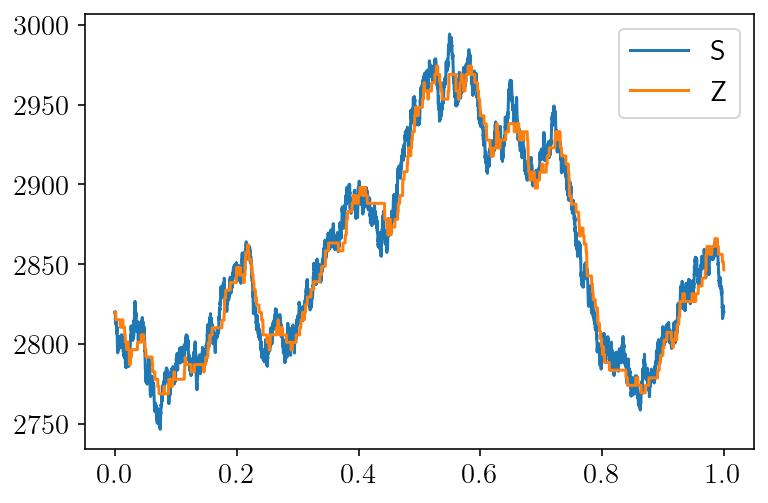

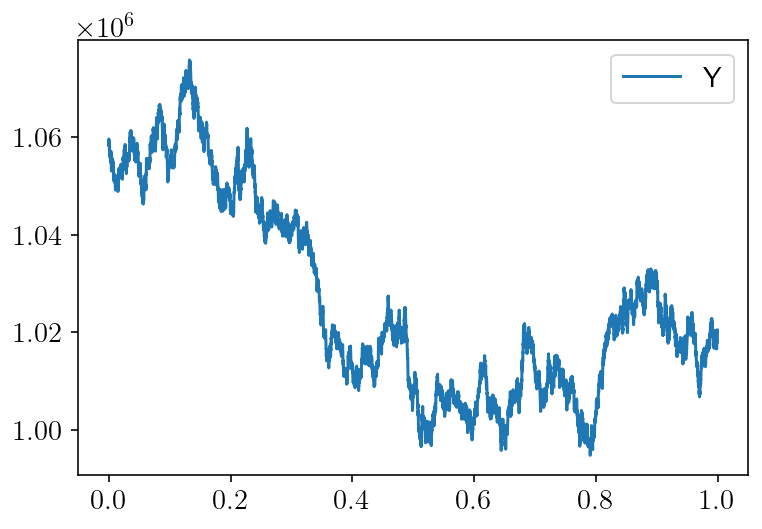

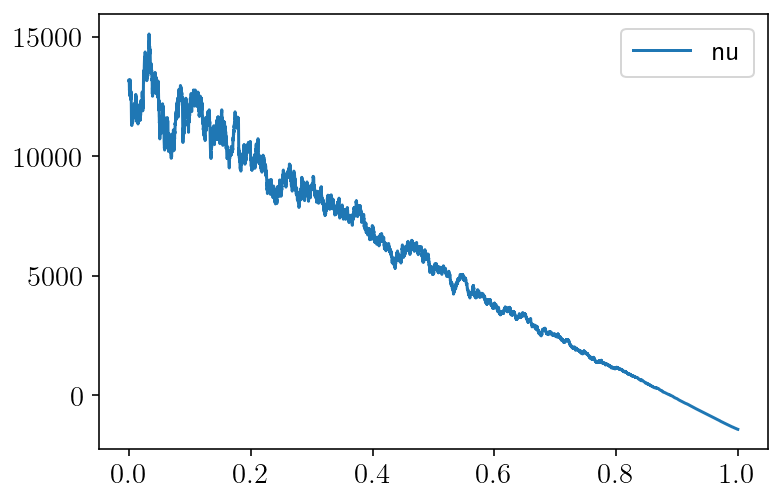

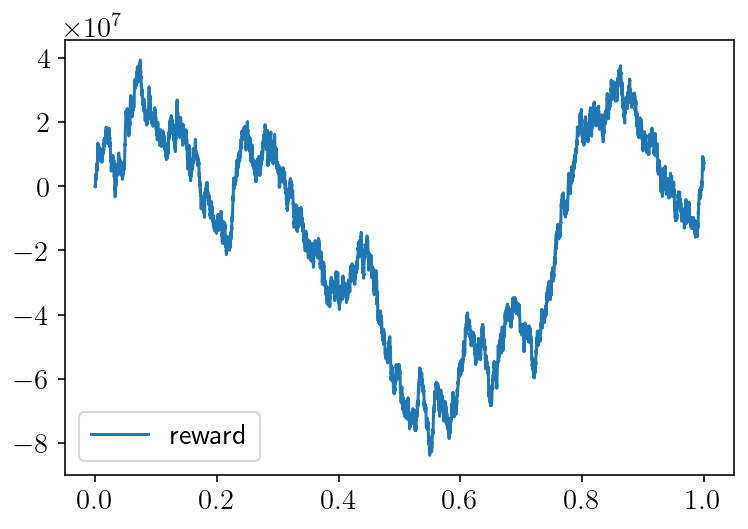

In [8]:
num_sim = 35

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()

# plt.plot(env.timesteps, -(env.T-env.timesteps)*np.abs(S[:,num_sim]-Z[:,num_sim]), label='-(T-t)*|S-Z|')
# plt.legend()
# plt.show()

plt.plot(env.timesteps[:], rew[:,num_sim], label='reward')
plt.legend()
plt.show()

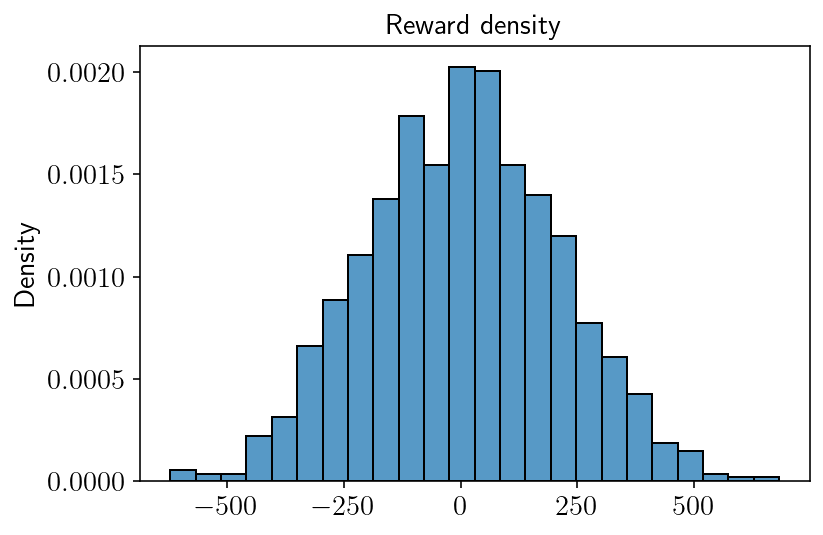

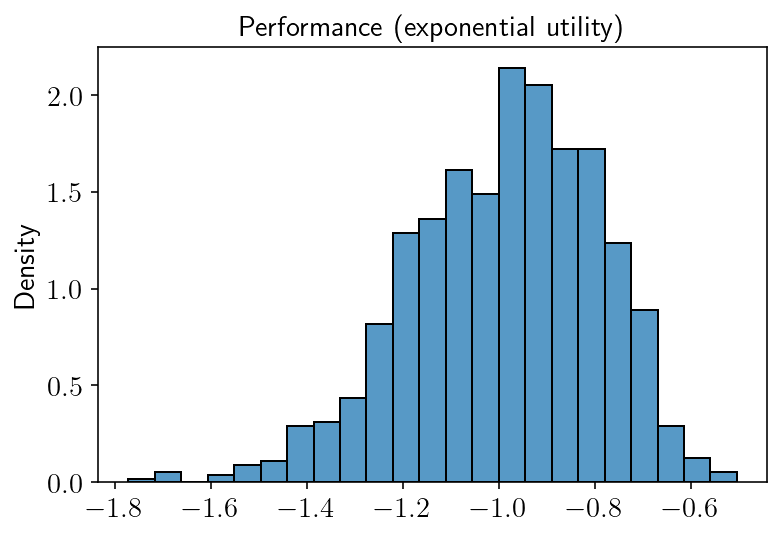

LP's expected performance (exponential utility, strag_LP:1, strag_vn:1): -0.98859
LP's expected wealth: 3.11603
Expected reward: 5.20081


In [8]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'LP\'s expected performance (exponential utility, strag_LP:{strag_LP}, strag_vn:{strag_vn}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

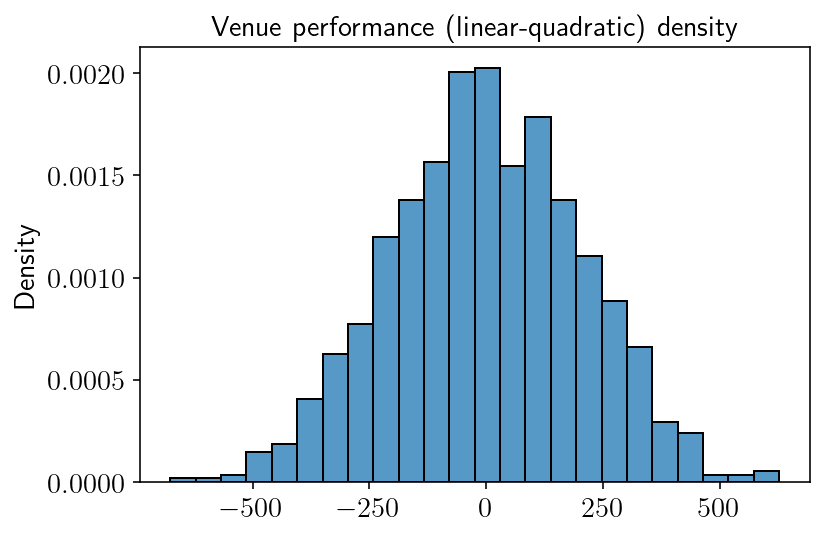

Venue's expected performance (LQ utility): 0.83002


In [9]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

In [10]:
np.exp(-env.gamma*env.P0)

0.9900498337491681

# LP does not trade

In [11]:
np.random.seed(100)

In [12]:
nsims = 1_000
strag_LP = '0'
strag_vn = '1'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = False)

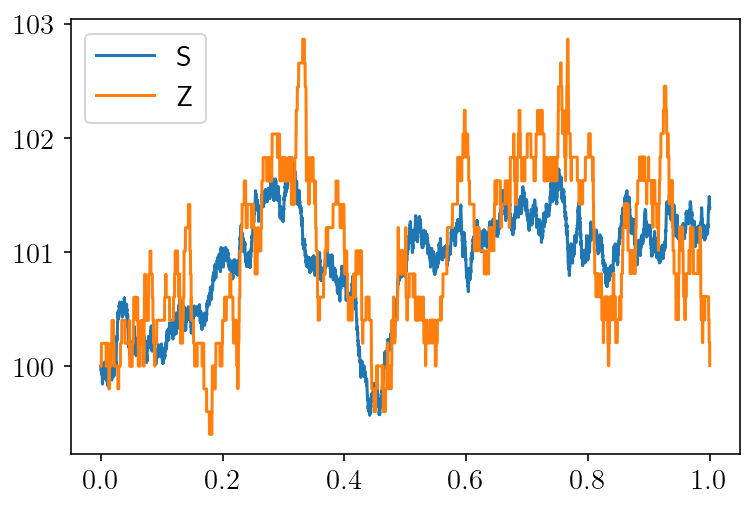

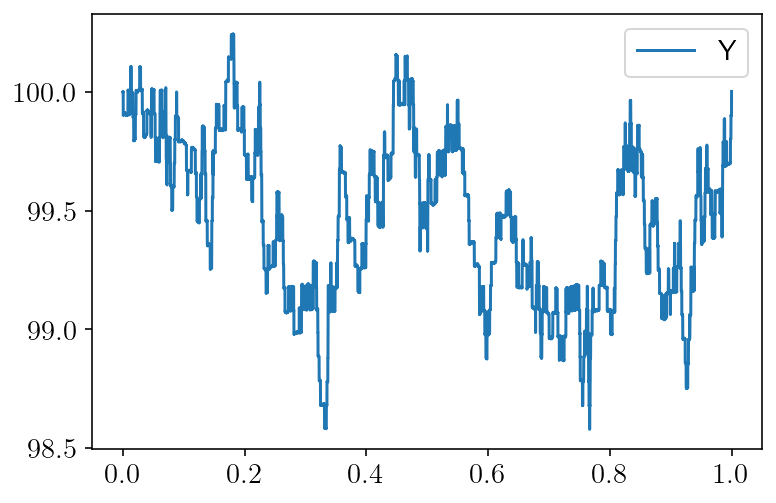

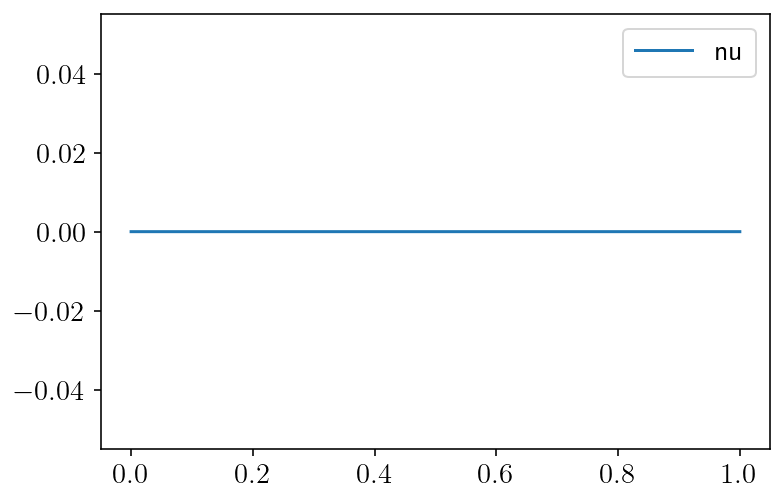

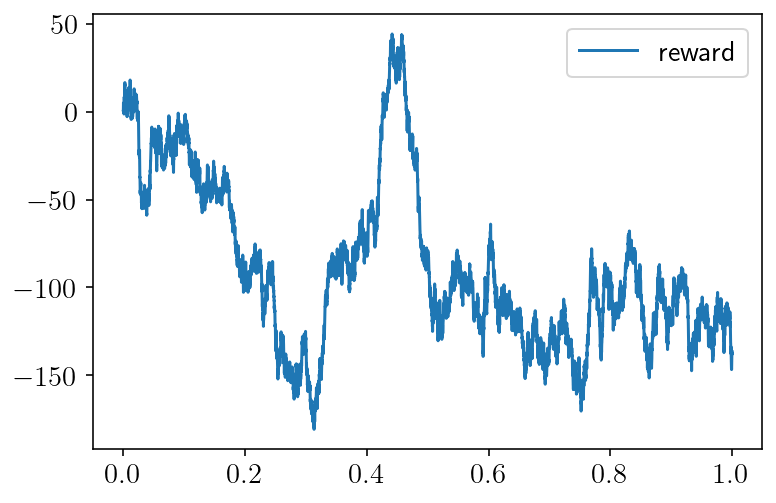

In [13]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

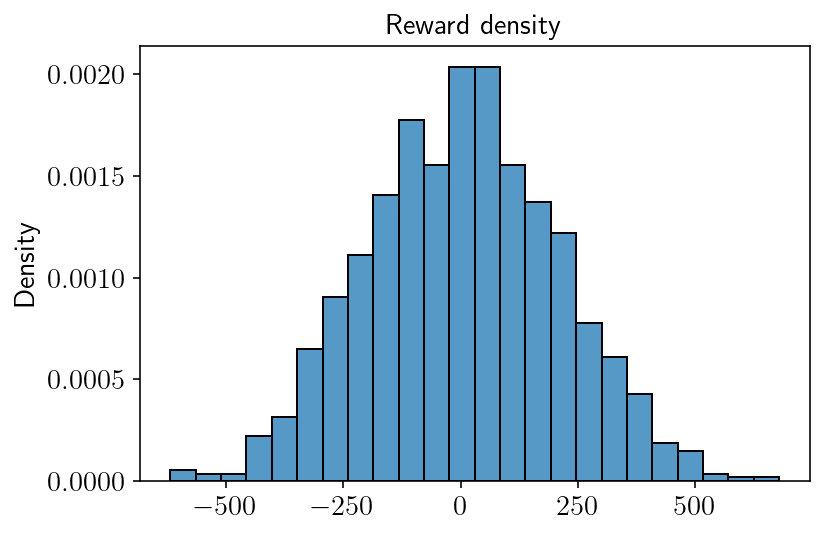

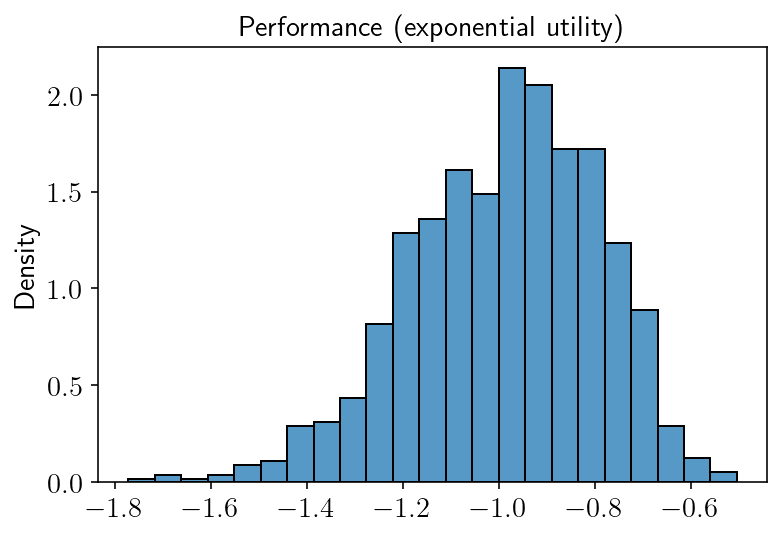

LP's expected performance (exponential utility, strag_LP:0, strag_vn:1): -0.98880
LP's expected wealth: 3.09531
Expected reward: 5.13969


In [14]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'LP\'s expected performance (exponential utility, strag_LP:{strag_LP}, strag_vn:{strag_vn}): {perf[0,:].mean():1.5f}')
print(f'LP\'s expected wealth: {wealth[0,:].mean():1.5f}')
print(f'Expected reward: {rew[-1,:].mean():1.5f}')

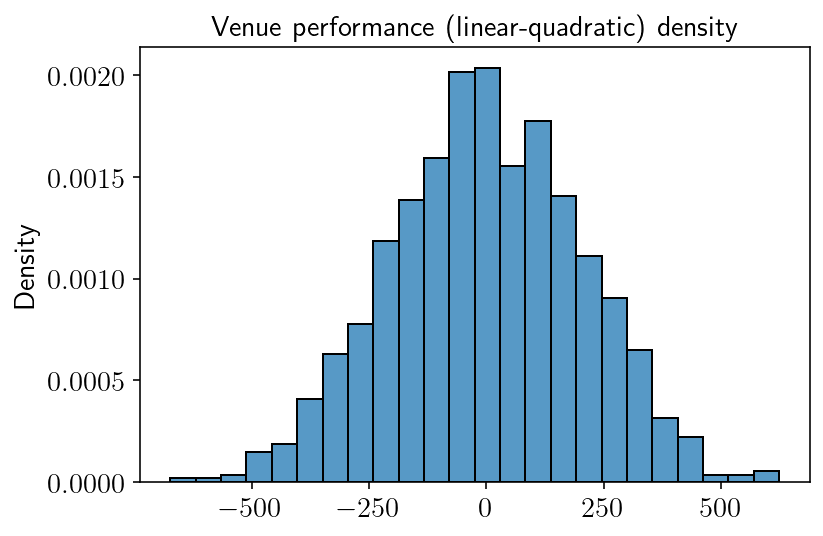

Venue's expected performance (LQ utility): 0.86906


In [15]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')

# Venue doesn't give reward

In [16]:
np.random.seed(100)

nsims = 1_000
strag_LP = '1'
strag_vn = '0'

S, Y, Z, X, nu, wealth, perf, rew, venue_wealth = env.simulate_venue(nsims=nsims, strag_LP=strag_LP, strag_vn=strag_vn, verbose = False)

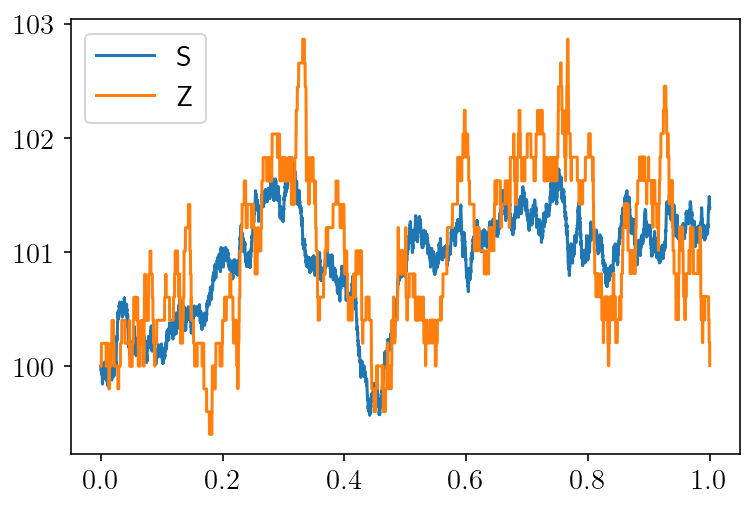

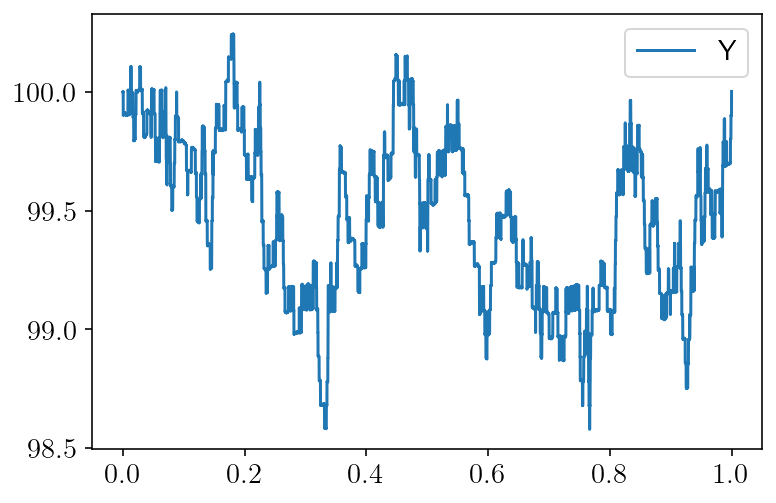

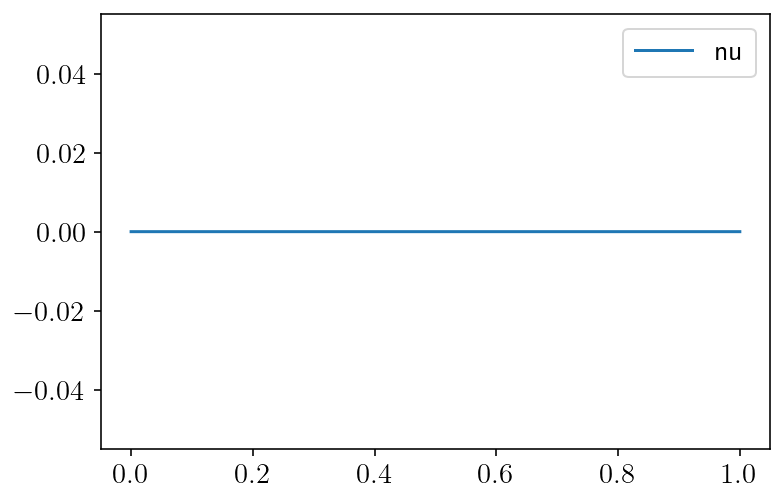

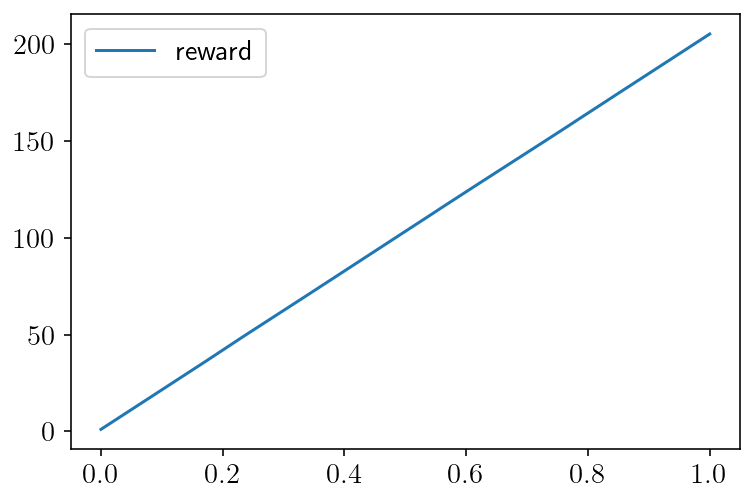

In [17]:
num_sim = 58

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()

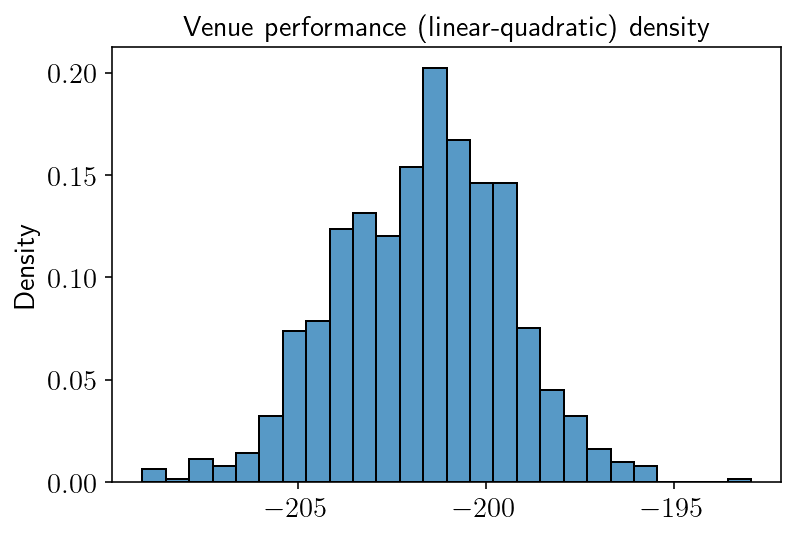

Venue's expected performance (LQ utility): -201.67812


In [18]:
sns.histplot(venue_wealth[0,:], stat='density')
plt.title("Venue performance (linear-quadratic) density")
plt.show()

print(f'Venue\'s expected performance (LQ utility): {venue_wealth[0,:].mean():1.5f}')